# Doubly robust causal survival analysis

Does adjuvant chemotherapy after surgery for stage III colon cancer buy
patients time, and how much? In a randomized trial you would compare the
arms directly. In routine-care data you cannot: older and frailer patients
are less often given chemotherapy *and* die sooner, so a naive comparison
credits the treatment with the better health of the patients who got it.

This tutorial estimates the causal effect from such observational data, as
the difference in **restricted mean survival time at 5 years**: the expected
number of years, out of the first five, that patients live with
chemotherapy versus with surgery alone. We use **augmented inverse
probability of treatment weighting** (AIPTW), a *doubly robust* estimator
built from two models:

- a **propensity score** model for who gets chemotherapy: logistic
  regression with NumPyro's Bernoulli likelihood;
- an **outcome** model for survival: a Weibull proportional hazards model
  with a survjax likelihood.

Administrative censoring is a **custom survjax distribution** of a few
lines. We will write the whole analysis as one pure function of the data,
so we can run the entire analysis on 1,000 bootstrap resamples in seconds
with a single `jax.vmap`.
The data are simulated, so we know the true answer.

This notebook is the runnable version of the [documentation page](../../docs/advanced/aiptw-rmst.md). It defines every analysis function in its own cell, so you can change one and rerun from there. Run it from anywhere inside the repository with the `examples` and `docs` groups:

```sh
uv run --group docs --group examples jupyter lab examples/aiptw_rmst/aiptw-rmst.ipynb
```

In [1]:
import sys
import warnings
from pathlib import Path
from typing import NamedTuple

import jax

jax.config.update("jax_enable_x64", True)  # the tutorial runs in float64
warnings.filterwarnings("ignore", message="IProgress not found")

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as distributions
import optimistix as optx
from IPython.display import display

import survjax

# Make the example package (examples/aiptw_rmst) importable from the repository root.
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT))
from examples.aiptw_rmst.cohort import (
    TAU,
    resample,
    simulate_cohort,
    true_death_model,
    true_rmst,
)
from examples.aiptw_rmst.reporting import markdown_table, standardized_difference

In [2]:
ARMS = ("Surgery alone", "Chemotherapy")
COLORS = ("C0", "C1")

## The cohort

We simulate 500 patients who had surgery for stage III colon cancer. Each has
three baseline covariates:

| Covariate | Affects chemotherapy? | Affects survival? |
| --- | --- | --- |
| **Age** | yes: older patients get it less often | yes: older patients die sooner |
| **Frailty** (performance status ≥ 2 or severe comorbidity) | yes, strongly | yes |
| **Stromal radiomic score (SRS)** | no | yes, mildly, and it modifies the chemotherapy effect |

Age and frailty are **confounders**. The SRS is a fictional imaging
biomarker. It is an AI score of how stroma-rich the tumour looks on the
preoperative CT. It was computed afterwards on archived scans, so clinicians
never saw it when choosing treatment. Stroma-rich tumours carry a somewhat
worse prognosis and gain a little less from chemotherapy. In the true model
the hazard ratio for chemotherapy is 0.70 at an average SRS and about 0.81
one standard deviation above it.

In [3]:
key = jax.random.PRNGKey(1)
data_key, bootstrap_key = jax.random.split(key)
data = simulate_cohort(data_key, n=500)
data.survival

SurvivalData: 500 observations, float64
    0  (4.18159, inf]
    1  4.90989
    2  (6.52584, inf]
    3  3.50479
    4  3.64255
    5  (6.35377, inf]
    6  (6.4178, inf]
    7  0.528573
    8  1.62491
    9  (6.32356, inf]
  ...
  495  1.21243
  496  (5.85188, inf]
  497  (5.02045, inf]
  498  4.0402
  499  (5.09598, inf]

Follow-up is purely administrative: patients entered the study over 4 years
and the analysis is at 8 years. So each patient's potential follow-up is
between 4 and 8 years, and anyone still alive then is censored. Treated and
untreated patients differ before any treatment effect:

In [4]:
age_years = 66 + 10 * data.covariates[:, 0]
baseline = {"Age (years)": age_years, "Frail (%)": 100 * data.covariates[:, 1],
            "SRS": data.covariates[:, 2]}
rows = []
for name, x in baseline.items():
    rows.append([name, *(f"{x[data.treated == a].mean():.1f}" for a in (0.0, 1.0)),
                 f"{standardized_difference(x, data.treated, jnp.ones(500)):+.2f}"])
rows.append(["Patients", *(f"{int((data.treated == a).sum())}" for a in (0.0, 1.0)), ""])
display(markdown_table(["", *ARMS, "Standardized difference"], rows))

|  | Surgery alone | Chemotherapy | Standardized difference |
| --- | --- | --- | --- |
| Age (years) | 69.6 | 63.2 | -0.70 |
| Frail (%) | 35.6 | 12.6 | -0.56 |
| SRS | 0.0 | -0.0 | -0.03 |
| Patients | 174 | 326 |  |

The chemotherapy patients are younger and less often frail. The SRS
played no part in the decision, so any difference between the arms is
chance alone.

## Censoring as a custom survival distribution

With administrative censoring, the follow-up window comes from the study
dates, so we do not need to estimate it. Potential follow-up is uniform
between 4 and 8 years, with censoring survival $G(t)=(8-t)/4$ inside that
window. survjax has no uniform family, so we wrote one,
`UniformFollowUp`, in
[follow_up.py](follow_up.py). It
takes a few short methods (see [custom distributions](../../docs/distributions.md)
for how). It is then a survjax distribution like any other, with batching,
`jit` and every derived method:

In [5]:
from examples.aiptw_rmst.follow_up import UniformFollowUp

FOLLOW_UP = UniformFollowUp(start=4.0, end=8.0)
t = jnp.array([3.0, 5.0, 7.0])
FOLLOW_UP.survival(t), FOLLOW_UP.hazard(t)

(Array([1.  , 0.75, 0.25], dtype=float64),
 Array([0.        , 0.33333333, 1.        ], dtype=float64))

## Who gets chemotherapy: the propensity score

The propensity score $e(x)=P(A=1\mid X=x)$ is a logistic regression of
treatment on an intercept and all three covariates. The analyst does not
know that the SRS is irrelevant to treatment, and including it costs little.
Both models in this tutorial are fitted by maximum likelihood with one small
helper around optimistix's BFGS:

In [6]:
def minimise(objective, start):
    """BFGS minimum of a smooth objective; returns (theta, converged)."""
    solution = optx.minimise(
        lambda theta, _: objective(theta),
        optx.BFGS(rtol=1e-8, atol=1e-8),
        start,
        max_steps=500,
        throw=False,  # report failure in `converged` instead, also under vmap
    )
    return solution.value, solution.result == optx.RESULTS.successful

NumPyro supplies the Bernoulli log likelihood of the logistic regression:

In [7]:
def fit_propensity(cohort):
    """Logistic regression of treatment on an intercept and the three covariates."""
    n = len(cohort.treated)
    X_matrix = jnp.column_stack([jnp.ones(n), cohort.covariates])  # (N, 4)

    def negative_log_likelihood(theta):
        treatment = distributions.Bernoulli(logits=X_matrix @ theta)
        return -treatment.log_prob(cohort.treated).sum()

    return minimise(negative_log_likelihood, jnp.zeros(X_matrix.shape[1]))

In [8]:
def propensity_scores(theta, covariates):
    """(N,) fitted probability of chemotherapy: intercept plus covariate effects."""
    return jax.nn.sigmoid(theta[0] + covariates @ theta[1:])

Weighting only works if every kind of patient could have received either
treatment (*positivity*). The fitted scores overlap well, with no patient
close to 0 or 1:

In [9]:
ps_theta, _ = fit_propensity(data)
propensity = propensity_scores(ps_theta, data.covariates)
print(f"propensity scores from {propensity.min():.2f} to {propensity.max():.2f}")

propensity scores from 0.12 to 0.95


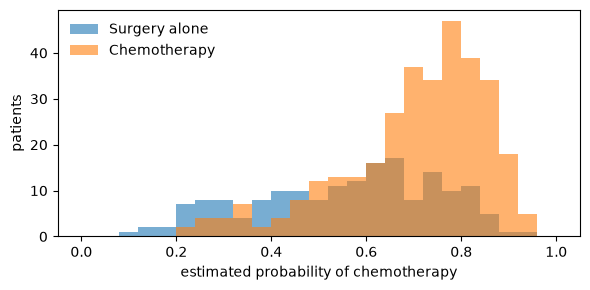

In [10]:
fig, ax = plt.subplots(figsize=(6, 3))
bins = np.linspace(0, 1, 26)
for a, (label, color) in enumerate(zip(ARMS, COLORS, strict=True)):
    ax.hist(propensity[data.treated == a], bins=bins, alpha=0.6, color=color, label=label)
ax.set(xlabel="estimated probability of chemotherapy", ylabel="patients")
ax.legend(frameon=False)
fig.tight_layout()

Weighting each patient by $1/\hat e$ (chemotherapy) or $1/(1-\hat e)$
(surgery alone) removes the imbalance in the confounders:

In [11]:
ipt_weight = jnp.where(data.treated == 1, 1 / propensity, 1 / (1 - propensity))
rows = [[name, f"{standardized_difference(x, data.treated, jnp.ones(500)):+.2f}",
         f"{standardized_difference(x, data.treated, ipt_weight):+.2f}"]
        for name, x in baseline.items()]
display(markdown_table(["Standardized difference", "Unweighted", "Weighted"], rows))

| Standardized difference | Unweighted | Weighted |
| --- | --- | --- |
| Age (years) | -0.70 | +0.06 |
| Frail (%) | -0.56 | -0.01 |
| SRS | -0.03 | +0.04 |

## What survival to expect: the outcome model

The outcome model is a Weibull proportional hazards model with treatment,
the three covariates and a prespecified treatment × SRS interaction, because
the marker is a candidate predictor of benefit. Its design matrix has one
row per patient and five columns:

In [12]:
def outcome_design_matrix(treated, covariates):
    """(N, 5) columns: chemo, age, frail, SRS and the chemo x SRS interaction."""
    treated = jnp.broadcast_to(treated, covariates.shape[:1])  # a scalar sets everyone
    srs = covariates[:, 2]
    return jnp.column_stack([treated, covariates, treated * srs])

The parameter vector `theta` holds the log shape, the log scale and the five
coefficients. Multiplying the design matrix by the coefficients gives every
patient's log hazard ratio, so one `ProportionalHazards` distribution holds
one survival model per patient:

In [13]:
def weibull_ph(theta, design_matrix):
    """theta = (log shape, log scale, coefficients): one distribution per row."""
    log_shape, log_scale = theta[:2]
    coefficients = theta[2:]
    baseline = survjax.Weibull.from_log(log_shape=log_shape, log_scale=log_scale)
    return survjax.ProportionalHazards(
        baseline=baseline, log_hazard_ratio=design_matrix @ coefficients
    )

In [14]:
def fit_weibull_ph(survival, design_matrix):
    """Maximum likelihood Weibull PH fit of right-censored survival times."""

    def negative_log_likelihood(theta):
        return -weibull_ph(theta, design_matrix).log_likelihood(survival).sum()

    # Start at shape 1, scale = mean observed time, and no covariate effects.
    start = jnp.zeros(2 + design_matrix.shape[1])
    start = start.at[1].set(jnp.log(survival.lower.mean()))
    return minimise(negative_log_likelihood, start)

We fit the model on the treatments the patients actually received:

In [15]:
observed_X = outcome_design_matrix(data.treated, data.covariates)  # (500, 5)
outcome_theta, _ = fit_weibull_ph(data.survival, observed_X)

From the fitted model we predict, for **every** patient, the 5-year RMST
they would have had under each treatment. We rebuild the design matrix with
the treatment column set to 0 for everyone, and then to 1 for everyone.
The covariates stay as observed. That is one closed-form `rmst` call on a
batch of 500 distributions per treatment:

In [16]:
def counterfactual_rmst(theta, covariates, treated):
    """(N,) model-based RMST(TAU) for every patient, had they all had `treated`."""
    # Same covariates, but the treatment column set to `treated` for everyone.
    counterfactual_X = outcome_design_matrix(treated, covariates)
    return weibull_ph(theta, counterfactual_X).rmst(TAU)

In [17]:
rmst_0 = counterfactual_rmst(outcome_theta, data.covariates, 0.0)  # (500,) surgery alone
rmst_1 = counterfactual_rmst(outcome_theta, data.covariates, 1.0)  # (500,) chemotherapy
rmst_0[:3], rmst_1[:3]

(Array([2.94900313, 3.92586927, 4.34577904], dtype=float64),
 Array([3.62315494, 4.36566505, 4.59406801], dtype=float64))

Averaging these over the cohort is the *g-formula* estimate. It is unbiased
only if the outcome model is right.

## The doubly robust estimator

Let $Y_i=\min(T_i, 5)$ be the restricted survival time, $\hat m_a(X_i)$ the
model RMST above and $\hat e_a$ the probability of the treatment $a$. AIPTW
starts from the outcome model and corrects it with the weighted residuals
of the patients who actually got treatment $a$:

$$
\hat\psi_a=\frac1n\sum_{i=1}^n\left[\hat m_a(X_i)
+\frac{\mathbb 1\{A_i=a\}\,\Delta_i}{\hat e_a(X_i)\,G(Y_i)}\bigl(Y_i-\hat m_a(X_i)\bigr)\right].
$$

Censoring adds one wrinkle. $Y_i$ is known only if the patient died before 5
years or was still followed at 5 years ($\Delta_i=1$). Those patients stand
in for the censored ones, through the inverse probability of censoring
weight $1/G(Y_i)$ from our custom distribution:

In [18]:
def censoring_weights(survival):
    """(N,) inverse probability of censoring weights, 0 when the status at TAU is unknown."""
    time = survival.lower
    known_by_tau = survival.exact | (time >= TAU)
    survived_censoring = FOLLOW_UP.survival(jnp.minimum(time, TAU))  # >= 0.75
    return jnp.where(known_by_tau, 1.0 / survived_censoring, 0.0)

In [19]:
def aiptw(outcome, ipcw, treated, propensity, rmst_0, rmst_1):
    """(2,) augmented IPTW mean of min(T, TAU): (surgery alone, chemotherapy)."""
    weight_0 = (1 - treated) * ipcw / (1 - propensity)
    weight_1 = treated * ipcw / propensity
    psi_0 = jnp.mean(rmst_0 + weight_0 * (outcome - rmst_0))
    psi_1 = jnp.mean(rmst_1 + weight_1 * (outcome - rmst_1))
    return jnp.stack([psi_0, psi_1])

$\hat\psi_a$ is consistent if *either* the propensity model *or* the outcome
model is correct. That is the double robustness.

## The whole analysis as one function

`analyse` takes the data and nothing else. It fits both models, predicts and
returns the per-arm RMST from four estimators. Besides the g-formula and
AIPTW, these are a naive comparison, a Weibull model with treatment only,
and IPTW, the weighted mean without the outcome model:

In [20]:
def naive_rmst(cohort):
    """(2,) RMST per arm from a Weibull PH model with treatment only."""
    theta, converged = fit_weibull_ph(cohort.survival, cohort.treated[:, None])
    per_arm = weibull_ph(theta, jnp.array([[0.0], [1.0]]))
    return per_arm.rmst(TAU), converged

In [21]:
def iptw(outcome, ipcw, treated, propensity):
    """(2,) weighted (Hajek) mean of min(T, TAU): (surgery alone, chemotherapy)."""
    weight_0 = (1 - treated) * ipcw / (1 - propensity)
    weight_1 = treated * ipcw / propensity
    psi_0 = jnp.sum(weight_0 * outcome) / jnp.sum(weight_0)
    psi_1 = jnp.sum(weight_1 * outcome) / jnp.sum(weight_1)
    return jnp.stack([psi_0, psi_1])

The results go into a named tuple, so that they stay a JAX pytree:

In [22]:
class Estimates(NamedTuple):
    """Per-arm RMST(TAU) in years, shape (2,) as (surgery alone, chemotherapy)."""

    naive: jax.Array
    g_formula: jax.Array
    iptw: jax.Array
    aiptw: jax.Array
    outcome_theta: jax.Array  # (7,) fitted outcome model, for effect-by-SRS curves
    converged: jax.Array

In [23]:
def analyse(data):
    """The whole analysis of one cohort: fit, predict and estimate.

    A pure function of the data, so it can be jitted and vmapped over
    bootstrap resamples.
    """
    ps_theta, ps_converged = fit_propensity(data)
    propensity = propensity_scores(ps_theta, data.covariates)

    observed_X = outcome_design_matrix(data.treated, data.covariates)
    outcome_theta, outcome_converged = fit_weibull_ph(data.survival, observed_X)
    rmst_0 = counterfactual_rmst(outcome_theta, data.covariates, 0.0)
    rmst_1 = counterfactual_rmst(outcome_theta, data.covariates, 1.0)

    outcome = jnp.minimum(data.survival.lower, TAU)  # min(T, TAU) where it is known
    ipcw = censoring_weights(data.survival)
    naive, naive_converged = naive_rmst(data)

    return Estimates(
        naive=naive,
        g_formula=jnp.stack([rmst_0.mean(), rmst_1.mean()]),
        iptw=iptw(outcome, ipcw, data.treated, propensity),
        aiptw=aiptw(outcome, ipcw, data.treated, propensity, rmst_0, rmst_1),
        outcome_theta=outcome_theta,
        converged=ps_converged & outcome_converged & naive_converged,
    )

In [24]:
estimates = jax.jit(analyse)(data)
for name in ("naive", "g_formula", "iptw", "aiptw"):
    rmst = getattr(estimates, name)
    print(f"{name:>9}: ΔRMST(5) = {rmst[1] - rmst[0]:.3f} years")

    naive: ΔRMST(5) = 0.705 years
g_formula: ΔRMST(5) = 0.406 years
     iptw: ΔRMST(5) = 0.413 years
    aiptw: ΔRMST(5) = 0.417 years


## Bootstrap confidence intervals in one `vmap`

Because `analyse` is a pure JAX function, the nonparametric bootstrap needs
no loop. We draw a table of patient indices, one row per replicate.
`resample` (from `cohort.py`) picks those rows out of every array in the
data. `jax.vmap` turns the analysis of one resample into the analysis of all
rows of the table at once, and `jax.jit` compiles that into a single
program. Each replicate refits both models from scratch:

In [25]:
def bootstrap(key, data, n_boot):
    """Analyse n_boot resamples with replacement in one vmapped, compiled call."""
    n = len(data.treated)
    indices = jax.random.randint(key, (n_boot, n), 0, n)  # one row per replicate

    def analyse_resample(idx):
        return analyse(resample(data, idx))

    analyse_all = jax.vmap(analyse_resample)  # over the rows of `indices`
    return jax.jit(analyse_all)(indices)

In [26]:
import time

start = time.perf_counter()
replicates = bootstrap(bootstrap_key, data, n_boot=1000)
replicates.aiptw.block_until_ready()
print(f"1000 bootstrap analyses in {time.perf_counter() - start:.1f} s, "
      f"{int(replicates.converged.sum())} with all fits converged")

1000 bootstrap analyses in 4.8 s, 1000 with all fits converged


## Results

The true values come from the simulation model, averaged over a million
simulated patients. The naive comparison has its own target, the difference
between the patients who happened to get each treatment:

In [27]:
truth = true_rmst(jax.random.PRNGKey(0), n_draws=1_000_000)
true_delta = float(truth["causal"][1] - truth["causal"][0])
naive_target = float(truth["naive"][1] - truth["naive"][0])

labels = {"naive": "Naive (unadjusted)", "g_formula": "g-formula",
          "iptw": "IPTW", "aiptw": "AIPTW"}
rows = []
for name, label in labels.items():
    point = getattr(estimates, name)
    draws = getattr(replicates, name)
    delta = draws[:, 1] - draws[:, 0]
    low, high = jnp.quantile(delta, jnp.array([0.025, 0.975]))
    rows.append([label, f"{point[0]:.2f}", f"{point[1]:.2f}",
                 f"{point[1] - point[0]:.3f}", f"[{low:.3f}, {high:.3f}]"])
rows.append(["**Truth**", f"{truth['causal'][0]:.2f}", f"{truth['causal'][1]:.2f}",
             f"**{true_delta:.3f}**", ""])
rows.append(["Target of the naive comparison", f"{truth['naive'][0]:.2f}",
             f"{truth['naive'][1]:.2f}", f"{naive_target:.3f}", ""])
display(markdown_table(["Estimator", "RMST(5), surgery", "RMST(5), chemo",
                        "ΔRMST(5) (years)", "95% bootstrap CI"], rows))

| Estimator | RMST(5), surgery | RMST(5), chemo | ΔRMST(5) (years) | 95% bootstrap CI |
| --- | --- | --- | --- | --- |
| Naive (unadjusted) | 3.59 | 4.30 | 0.705 | [0.477, 0.962] |
| g-formula | 3.80 | 4.21 | 0.406 | [0.191, 0.647] |
| IPTW | 3.82 | 4.23 | 0.413 | [0.136, 0.728] |
| AIPTW | 3.79 | 4.20 | 0.417 | [0.141, 0.722] |
| **Truth** | 3.85 | 4.11 | **0.266** |  |
| Target of the naive comparison | 3.64 | 4.23 | 0.592 |  |

In truth, chemotherapy adds about a quarter of a year, roughly 3 months,
of life in the first five years. The naive comparison more than doubles
that, because it also credits chemotherapy with the younger, fitter
patients who received it. Its interval misses the truth. The intervals of
the adjusted estimators all contain it, and AIPTW gets there while needing
only one of its two models to be right.

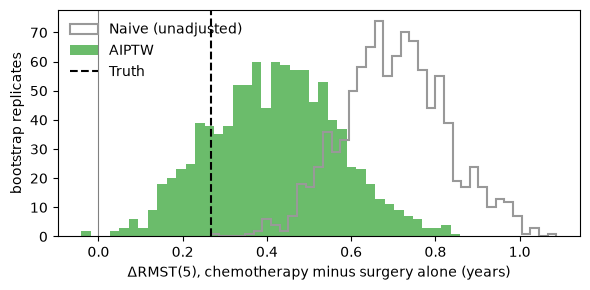

In [28]:
fig, ax = plt.subplots(figsize=(6, 3))
for name, color in (("naive", "0.6"), ("aiptw", "C2")):
    draws = getattr(replicates, name)
    style = {"histtype": "step", "linewidth": 1.5} if name == "naive" else {"alpha": 0.7}
    ax.hist(draws[:, 1] - draws[:, 0], bins=40, color=color, label=labels[name], **style)
ax.axvline(true_delta, color="black", linestyle="--", label="Truth")
ax.axvline(0, color="0.5", linewidth=0.8)
ax.set(xlabel="ΔRMST(5), chemotherapy minus surgery alone (years)", ylabel="bootstrap replicates")
ax.legend(frameon=False)
fig.tight_layout()

The outcome model also gives *standardized* survival curves: each
patient's predicted curve under one treatment, averaged over the whole
cohort. The area under each curve up to the dotted line at 5 years is the
g-formula RMST:

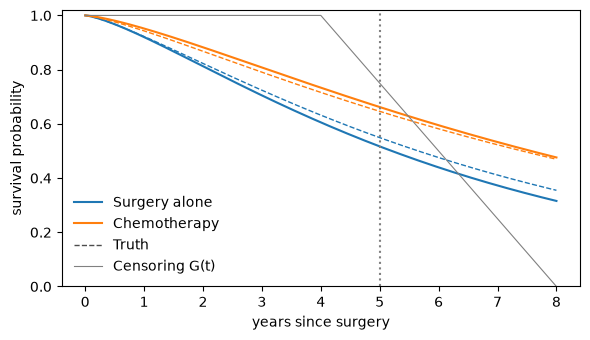

In [29]:
times = jnp.linspace(0.0, 8.0, 161)
fig, ax = plt.subplots(figsize=(6, 3.5))
for a, (label, color) in enumerate(zip(ARMS, COLORS, strict=True)):
    fitted = weibull_ph(outcome_theta, outcome_design_matrix(float(a), data.covariates))
    true_curve = true_death_model(data.covariates, float(a)).survival_grid(times).mean(axis=1)
    curve = fitted.survival_grid(times).mean(axis=1)  # (161, 500) -> (161,)
    ax.plot(times, curve, color=color, label=label)
    ax.plot(times, true_curve, color=color, linestyle="--", linewidth=1)
ax.plot([], [], color="0.3", linestyle="--", linewidth=1, label="Truth")
ax.plot(times, FOLLOW_UP.survival(times), color="0.5", linewidth=0.8, label="Censoring G(t)")
ax.axvline(TAU, color="0.5", linestyle=":")
ax.set(xlabel="years since surgery", ylabel="survival probability", ylim=(0, 1.02))
ax.legend(frameon=False, loc="lower left")
fig.tight_layout()

## Who benefits most?

The interaction in the outcome model lets us ask how the benefit varies with
the SRS. Here it is for a patient aged 66 who is not frail. Every bootstrap
replicate carries its own fitted outcome model, so the band costs one more
`vmap`:

In [30]:
srs = jnp.linspace(-2.0, 2.0, 41)
reference = jnp.column_stack([jnp.zeros_like(srs), jnp.zeros_like(srs), srs])  # age 66, not frail


def benefit_by_srs(theta):
    """(41,) model-based ΔRMST(5) along the SRS grid, for one fitted outcome model."""
    return (counterfactual_rmst(theta, reference, 1.0)
            - counterfactual_rmst(theta, reference, 0.0))


band = jax.vmap(benefit_by_srs)(replicates.outcome_theta)  # (1000, 41)

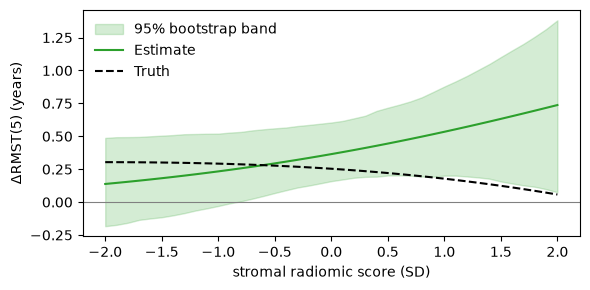

In [31]:
true_benefit = (true_death_model(reference, 1.0).rmst(TAU)
                - true_death_model(reference, 0.0).rmst(TAU))
low, high = jnp.quantile(band, jnp.array([0.025, 0.975]), axis=0)
fig, ax = plt.subplots(figsize=(6, 3))
ax.fill_between(srs, low, high, color="C2", alpha=0.2, label="95% bootstrap band")
ax.plot(srs, benefit_by_srs(outcome_theta), color="C2", label="Estimate")
ax.plot(srs, true_benefit, color="black", linestyle="--", label="Truth")
ax.axhline(0, color="0.5", linewidth=0.8)
ax.set(xlabel="stromal radiomic score (SD)", ylabel="ΔRMST(5) (years)")
ax.legend(frameon=False)
fig.tight_layout()

In truth the benefit shrinks as the SRS rises. With 500 patients, though, a
treatment × marker interaction is poorly determined. In this cohort the
estimate even slopes the wrong way, and the band is wide enough to hold
either direction. Read such a curve as a description, not as evidence of
who benefits; that needs far more patients.

## Takeaways

- A causal survival analysis is a handful of small, separate functions: a
  propensity model, an outcome model, a censoring distribution and an
  estimator. survjax supplies the censored likelihood, the per-patient
  RMST and the custom distribution. NumPyro and optimistix do the rest.
- Writing the analysis as one pure function of the data makes the
  bootstrap a `vmap`. A thousand complete reanalyses take seconds.
- Every analysis function is defined in this notebook;
  [analysis.py](analysis.py) has them
  in one file with their imports. The simulation and the true values are in
  [cohort.py](cohort.py), and the
  censoring distribution is in
  [follow_up.py](follow_up.py).

This analysis assumes no unmeasured confounding and positivity. The
simulation guarantees both, but real data do not. The AIPTW estimator here
weights the censoring with a known distribution. The fully efficient
version adds a censoring augmentation term: patients censored before 5 years
then count through their model-predicted RMST given survival to their
censoring time, which narrows the interval (Tsiatis, *Semiparametric Theory
and Missing Data*, Springer 2006, chapters 9 and 10).